# Section 6: Transformer Foundations

**Student:** WuShangxuan  
**GitHub username:** WuShangxuan0106  
**Date:** 2026-10-12

This notebook studies a small character-level Transformer for predicting the
HOMO-LUMO gap from polymer PSMILES strings. The final test rows are held out
until the model, preprocessing rules, and checkpoint rule have been fixed.

## 0. Setup and reproducibility

The notebook uses repository-relative paths and runs from the repository root.
All random seeds are fixed. The tiny model is intentionally CPU-sized so the
same notebook can be rerun on a laptop.

In [1]:
from __future__ import annotations

from copy import deepcopy
from pathlib import Path
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

GLOBAL_SEED = 42
SPLIT_SEED = 42
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
TARGET = "HOMO_LUMO_Gap_eV"
DEVICE = torch.device("cpu")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

def set_seed(seed: int = GLOBAL_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

set_seed(GLOBAL_SEED)
print("numpy", np.__version__)
print("torch", torch.__version__)
print("device", DEVICE)

numpy 2.5.2
torch 2.13.0
device cpu


## 1. Data audit and token statistics

The modeling row is one calculated polymer record. Rows with
`Energy_Hatree == 0` are treated as failed calculations, matching the Section 3
baseline rule. The sequence input is `psmiles`; the target is
`HOMO_LUMO_Gap_eV` in eV.

In [2]:
def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "sections").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root")

REPO_ROOT = find_repo_root()
DATA_PATH = REPO_ROOT / "sections/s02/homework/openpoly_calculated_properties.csv"
raw_df = pd.read_csv(DATA_PATH)

valid_mask = raw_df["Energy_Hatree"].ne(0.0) & raw_df["psmiles"].notna() & raw_df[TARGET].notna()
df = raw_df.loc[valid_mask].reset_index(drop=True).copy()
df["sequence_length"] = df["psmiles"].astype(str).str.len()

print("raw rows:", len(raw_df))
print("removed rows with Energy_Hatree == 0:", int((raw_df["Energy_Hatree"] == 0).sum()))
print("valid modeling rows:", len(df))
print("target unit: eV")
print("unique PSMILES:", df["psmiles"].nunique())

target_summary = df[TARGET].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
length_summary = df["sequence_length"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
print("\nTarget summary:")
print(target_summary.round(4).to_string())
print("\nSequence-length summary:")
print(length_summary.round(2).to_string())

q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
target_outliers = df[(df[TARGET] < q1 - 1.5 * iqr) | (df[TARGET] > q3 + 1.5 * iqr)]
print("\nTarget IQR outliers:", len(target_outliers))
print(target_outliers[["id", "Name", "sequence_length", TARGET]].to_string(index=False))

raw rows: 1000
removed rows with Energy_Hatree == 0: 74
valid modeling rows: 926
target unit: eV
unique PSMILES: 926

Target summary:
count    926.0000
mean       8.3081
std        0.4814
min        4.4689
25%        8.0222
50%        8.3395
75%        8.6126
95%        8.9850
99%        9.6735
max       10.0010

Sequence-length summary:
count    926.00
mean      53.49
std        9.17
min       35.00
25%       47.00
50%       52.00
75%       58.00
95%       71.75
99%       80.75
max       98.00

Target IQR outliers: 26
 id               Name  sequence_length  HOMO_LUMO_Gap_eV
  3 OMG_polymer_105232               37           10.0010
160 OMG_polymer_168059               55            9.7729
199  OMG_polymer_97237               50            9.8756
236 OMG_polymer_192331               55            9.6632
298 OMG_polymer_150234               47            9.8169
300 OMG_polymer_148088               57            6.5123
395 OMG_polymer_164834               53            9.6770
439 OMG_pol

/var/folders/7c/jdc732g90mq3htnp6mq_k1rc0000gn/T/ipykernel_48633/3859607518.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df[TARGET], vert=True, patch_artist=True, boxprops={"facecolor": "#dd8452"})


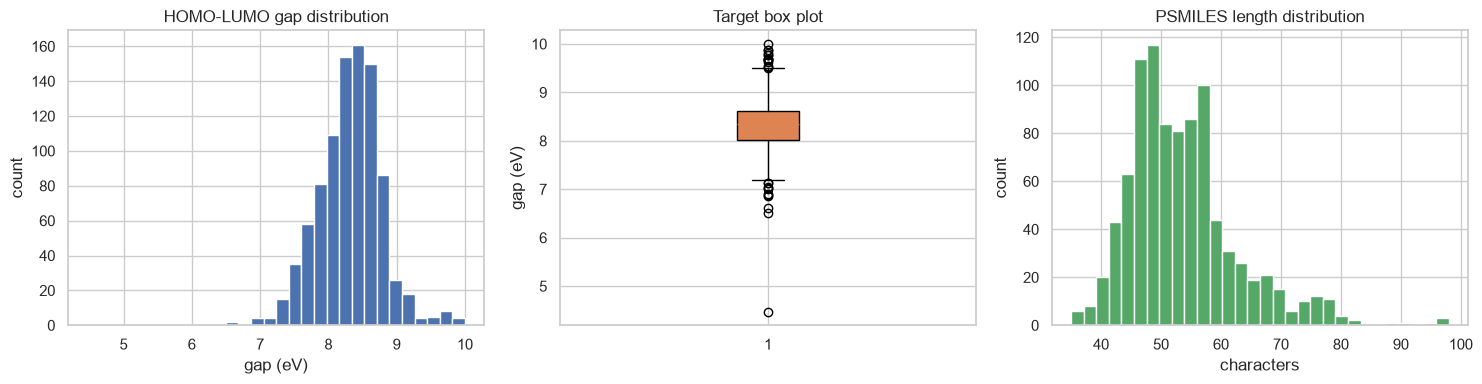

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df[TARGET], bins=30, color="#4c72b0", edgecolor="white")
axes[0].set(title="HOMO-LUMO gap distribution", xlabel="gap (eV)", ylabel="count")

axes[1].boxplot(df[TARGET], vert=True, patch_artist=True, boxprops={"facecolor": "#dd8452"})
axes[1].set(title="Target box plot", ylabel="gap (eV)")

axes[2].hist(df["sequence_length"], bins=30, color="#55a868", edgecolor="white")
axes[2].set(title="PSMILES length distribution", xlabel="characters", ylabel="count")

plt.tight_layout()
plt.show()

In [4]:
relationship_rows = []
for name, values in {
    "sequence_length": df["sequence_length"],
}.items():
    relationship_rows.append({
        "variable": name,
        "pearson_with_target": df[TARGET].corr(values, method="pearson"),
        "spearman_with_target": df[TARGET].corr(values, method="spearman"),
    })

numeric_candidates = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in {"id", TARGET, "sequence_length"}
]
numeric_corr = (
    df[numeric_candidates + [TARGET]]
    .corr(method="pearson")[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

print("Relationship with sequence length:")
print(pd.DataFrame(relationship_rows).round(4).to_string(index=False))
print("\nLargest absolute numeric correlations with the target:")
print(numeric_corr.head(12).round(4).to_string())
print("\nLeakage warning: HOMO_eV and LUMO_eV are shown only for diagnosis and are excluded from all sequence models.")

Relationship with sequence length:
       variable  pearson_with_target  spearman_with_target
sequence_length              -0.0983               -0.0735

Largest absolute numeric correlations with the target:
HOMO_eV                                          -0.6450
LUMO_eV                                           0.6436
Isotropic_Polarizability_au                      -0.2283
es                                               -0.1307
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.0784
Dipole_Debye                                     -0.0522
Entropy_Hatree                                    0.0337
Gibbs_Free_Energy_Hatree                          0.0134
Energy_Hatree                                     0.0134
Enthalpy_Hatree                                   0.0134
Inner_energy_correction_Hatree                   -0.0001
Thermal_correction_to_Enthalpy_Hatree                NaN

Leakage warning: HOMO_eV and LUMO_eV are shown only for diagnosis and are excluded from all sequence model

### Fixed split and character vocabulary

The split is 60/20/20 for train/validation/test. The vocabulary, maximum token
length, target scaler, and model choices are learned from the training split
only. Validation chooses the checkpoint; the test set is used once at the end.

In [5]:
indices = np.arange(len(df))
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SPLIT_SEED,
)
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.25,
    random_state=SPLIT_SEED,
)

def assert_disjoint(*index_arrays) -> None:
    sets = [set(map(int, idx)) for idx in index_arrays]
    for i in range(len(sets)):
        for j in range(i + 1, len(sets)):
            assert sets[i].isdisjoint(sets[j]), f"Split {i} and split {j} overlap"

assert_disjoint(train_idx, val_idx, test_idx)
print("split sizes:", len(train_idx), len(val_idx), len(test_idx))
print("target by split:")
for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    values = df.loc[idx, TARGET]
    print(f"  {name:10s} n={len(idx):3d} mean={values.mean():.4f} std={values.std(ddof=1):.4f} min={values.min():.4f} max={values.max():.4f}")

split sizes: 555 185 186
target by split:
  train      n=555 mean=8.3051 std=0.4697 min=6.5123 max=9.8756
  validation n=185 mean=8.3139 std=0.4748 min=6.8784 max=10.0010
  test       n=186 mean=8.3116 std=0.5230 min=4.4689 max=9.6941


In [6]:
train_sequences = df.loc[train_idx, "psmiles"].astype(str).tolist()
train_lengths = np.array([len(s) for s in train_sequences], dtype=int)
MAX_LEN = int(np.percentile(train_lengths, 99))

chars = sorted(set("".join(train_sequences)))
vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for ch in chars:
    if ch not in vocab:
        vocab[ch] = len(vocab)
inv_vocab = {idx: token for token, idx in vocab.items()}
PAD_IDX = vocab[PAD_TOKEN]
UNK_IDX = vocab[UNK_TOKEN]

def encode_sequence(text: str, max_len: int = MAX_LEN) -> np.ndarray:
    ids = [vocab.get(ch, UNK_IDX) for ch in str(text)[:max_len]]
    ids = ids + [PAD_IDX] * (max_len - len(ids))
    return np.asarray(ids, dtype=np.int64)

def encode_many(texts) -> np.ndarray:
    return np.stack([encode_sequence(s) for s in texts])

X_train = encode_many(df.loc[train_idx, "psmiles"])
X_val = encode_many(df.loc[val_idx, "psmiles"])
X_test = encode_many(df.loc[test_idx, "psmiles"])

y_train_raw = df.loc[train_idx, TARGET].to_numpy(np.float32)
y_val_raw = df.loc[val_idx, TARGET].to_numpy(np.float32)
y_test_raw = df.loc[test_idx, TARGET].to_numpy(np.float32)

y_scaler = StandardScaler().fit(y_train_raw.reshape(-1, 1))
y_train = y_scaler.transform(y_train_raw.reshape(-1, 1)).ravel().astype(np.float32)
y_val = y_scaler.transform(y_val_raw.reshape(-1, 1)).ravel().astype(np.float32)
y_test = y_scaler.transform(y_test_raw.reshape(-1, 1)).ravel().astype(np.float32)

print("vocabulary size:", len(vocab))
print("training percentiles for PSMILES length:")
for p in [50, 75, 90, 95, 99, 100]:
    print(f"  p{p:>3}: {np.percentile(train_lengths, p):.0f}")
print("chosen MAX_LEN:", MAX_LEN)
print("encoded train shape:", X_train.shape)
print("target scaler mean/std:", float(y_scaler.mean_[0]), float(np.sqrt(y_scaler.var_[0])))

vocabulary size: 30
training percentiles for PSMILES length:
  p 50: 52
  p 75: 58
  p 90: 66
  p 95: 72
  p 99: 78
  p100: 98
chosen MAX_LEN: 78
encoded train shape: (555, 78)
target scaler mean/std: 8.305065784798012 0.46928486444529227


In [7]:
token_counts = X_train.astype(bool).sum(axis=1)
print("Training token-count summary:")
print(pd.Series(token_counts, name="non-pad tokens").describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_string())
print("\nMost common training characters and their counts:")
char_counts = pd.Series(list("".join(train_sequences))).value_counts()
print(char_counts.head(15).to_string())
print("\nVocabulary:", vocab)

Training token-count summary:
count    555.00
mean      53.36
std        8.74
min       35.00
25%       47.00
50%       52.00
75%       58.00
95%       72.30
99%       78.00
max       78.00

Most common training characters and their counts:
c    6261
(    4183
)    4183
C    3930
O    2812
=    2103
N    1462
1    1432
*    1110
2     716
F     273
S     214
n     197
3     154
B     147

Vocabulary: {'<pad>': 0, '<unk>': 1, '#': 2, '(': 3, ')': 4, '*': 5, '-': 6, '1': 7, '2': 8, '3': 9, '4': 10, '5': 11, '6': 12, '7': 13, '=': 14, 'B': 15, 'C': 16, 'F': 17, 'H': 18, 'N': 19, 'O': 20, 'S': 21, '[': 22, ']': 23, 'c': 24, 'l': 25, 'n': 26, 'o': 27, 'r': 28, 's': 29}


## 2. Scaled dot-product attention with shape checks

The implementation below follows
`softmax(Q K^T / sqrt(d_k)) V`. A boolean key-padding mask marks padded tokens so
they cannot receive attention weight.

In [8]:
def scaled_dot_product_attention(q, k, v, key_padding_mask=None):
    if q.ndim != 4 or k.ndim != 4 or v.ndim != 4:
        raise ValueError("q, k, and v must have shape (batch, heads, tokens, head_dim)")
    if q.shape[:-1] != k.shape[:-1]:
        raise ValueError("q and k must agree on batch, heads, and query/key length")
    if k.shape[-1] != v.shape[-1]:
        raise ValueError("k and v must have the same head dimension")
    if k.shape[-2] != v.shape[-2]:
        raise ValueError("k and v must have the same key/value length")

    head_dim = q.shape[-1]
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(head_dim)
    if key_padding_mask is not None:
        if key_padding_mask.shape != scores.shape:
            raise ValueError("key_padding_mask must broadcast to the score shape")
        scores = scores.masked_fill(key_padding_mask, -1e9)
    attention_weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(attention_weights, v)
    return output, attention_weights

set_seed(GLOBAL_SEED)
batch_size, heads, tokens, head_dim = 3, 4, 7, 5
q = torch.randn(batch_size, heads, tokens, head_dim)
k = torch.randn(batch_size, heads, tokens, head_dim)
v = torch.randn(batch_size, heads, tokens, head_dim)
pad = torch.zeros(batch_size, tokens, dtype=torch.bool)
pad[0, -2:] = True
pad[2, -1:] = True
ignore_mask = pad[:, None, None, :].expand(batch_size, heads, tokens, tokens)

out, weights = scaled_dot_product_attention(q, k, v, ignore_mask)
reference = F.scaled_dot_product_attention(q, k, v, attn_mask=~pad[:, None, None, :])

print("q/k/v shapes:", tuple(q.shape), tuple(k.shape), tuple(v.shape))
print("attention weight shape:", tuple(weights.shape))
print("output shape:", tuple(out.shape))
print("row sums (first example):", weights[0].sum(dim=-1).detach().numpy().round(5))
print("max absolute difference from PyTorch reference:", float((out - reference).abs().max()))
assert weights.shape == (batch_size, heads, tokens, tokens)
assert out.shape == v.shape
assert torch.allclose(out, reference, atol=1e-5)

q/k/v shapes: (3, 4, 7, 5) (3, 4, 7, 5) (3, 4, 7, 5)
attention weight shape: (3, 4, 7, 7)
output shape: (3, 4, 7, 5)
row sums (first example): [[1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]]
max absolute difference from PyTorch reference: 2.384185791015625e-07


## 3. Tiny Transformer regressor

The model uses learned token and position embeddings, two pre-normalized
multi-head attention blocks, mean pooling over non-padding tokens, and a small
regression head. It is deliberately small because the dataset has fewer than
1,000 valid rows.

In [9]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model: int, nhead: int, dropout: float):
        super().__init__()
        if d_model % nhead != 0:
            raise ValueError("d_model must be divisible by nhead")
        self.d_model = d_model
        self.nhead = nhead
        self.head_dim = d_model // nhead
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, key_padding_mask=None, need_weights=False):
        batch, tokens, _ = x.shape
        qkv = self.qkv(x)
        q, k, v = qkv.chunk(3, dim=-1)

        def split_heads(t):
            return t.view(batch, tokens, self.nhead, self.head_dim).transpose(1, 2)

        q, k, v = split_heads(q), split_heads(k), split_heads(v)
        ignore_mask = None
        if key_padding_mask is not None:
            ignore_mask = key_padding_mask[:, None, None, :].expand(batch, self.nhead, tokens, tokens)

        if need_weights:
            out, weights = scaled_dot_product_attention(q, k, v, ignore_mask)
        else:
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=None if ignore_mask is None else ~ignore_mask)
            weights = None

        out = out.transpose(1, 2).contiguous().view(batch, tokens, self.d_model)
        return self.out_proj(self.dropout(out)), weights


class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, nhead: int, dim_feedforward: int, dropout: float):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = MultiHeadSelfAttention(d_model, nhead, dropout)
        self.dropout1 = nn.Dropout(dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim_feedforward, d_model),
        )
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, key_padding_mask=None, need_weights=False):
        attended, weights = self.attention(self.norm1(x), key_padding_mask, need_weights=need_weights)
        x = x + self.dropout1(attended)
        x = x + self.dropout2(self.feed_forward(self.norm2(x)))
        return x, weights


class TinyTransformerRegressor(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        max_len: int,
        d_model: int = 64,
        nhead: int = 4,
        num_layers: int = 2,
        dim_feedforward: int = 128,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.max_len = max_len
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.position_embedding = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, nhead, dim_feedforward, dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.regression_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, 1),
        )

    def encode(self, tokens):
        batch, seq_len = tokens.shape
        positions = torch.arange(seq_len, device=tokens.device).unsqueeze(0).expand(batch, seq_len)
        padding_mask = tokens.eq(PAD_IDX)
        x = self.token_embedding(tokens) + self.position_embedding(positions)

        for block in self.blocks:
            x, _ = block(x, key_padding_mask=padding_mask)

        x = self.final_norm(x)
        valid = (~padding_mask).unsqueeze(-1).to(x.dtype)
        pooled = (x * valid).sum(dim=1) / valid.sum(dim=1).clamp_min(1.0)
        return pooled

    def forward(self, tokens, return_attention=False):
        batch, seq_len = tokens.shape
        positions = torch.arange(seq_len, device=tokens.device).unsqueeze(0).expand(batch, seq_len)
        padding_mask = tokens.eq(PAD_IDX)
        x = self.token_embedding(tokens) + self.position_embedding(positions)
        attention_weights = None

        for layer_index, block in enumerate(self.blocks):
            x, weights = block(
                x,
                key_padding_mask=padding_mask,
                need_weights=return_attention and layer_index == 0,
            )
            if weights is not None:
                attention_weights = weights

        x = self.final_norm(x)
        valid = (~padding_mask).unsqueeze(-1).to(x.dtype)
        pooled = (x * valid).sum(dim=1) / valid.sum(dim=1).clamp_min(1.0)
        return self.regression_head(pooled).squeeze(-1), attention_weights


def parameter_count(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

set_seed(GLOBAL_SEED)
probe_model = TinyTransformerRegressor(len(vocab), MAX_LEN)
probe_logits, probe_attention = probe_model(torch.from_numpy(X_train[:4]), return_attention=True)
print("parameter count:", parameter_count(probe_model))
print("logit shape:", tuple(probe_logits.shape))
print("first-layer attention shape:", tuple(probe_attention.shape))

parameter count: 78209
logit shape: (4,)
first-layer attention shape: (4, 4, 78, 78)


### Training contract

| Item | Choice |
|---|---|
| Input | PSMILES character ids, training vocabulary and maximum length |
| Target | `HOMO_LUMO_Gap_eV`, standardized with training rows only |
| Loss | mean squared error on standardized targets |
| Optimizer | AdamW, learning rate `1e-3`, weight decay `1e-4` |
| Batch size | 32 |
| Epochs | 50 |
| Checkpoint | lowest validation RMSE |
| Seed | 42 |

No test row is used for vocabulary construction, target scaling, model choice,
or checkpoint selection.

In [10]:
def make_loader(tokens: np.ndarray, targets: np.ndarray, batch_size: int, shuffle: bool) -> DataLoader:
    dataset = TensorDataset(
        torch.from_numpy(tokens.astype(np.int64)),
        torch.from_numpy(targets.astype(np.float32)),
    )
    generator = torch.Generator().manual_seed(GLOBAL_SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator if shuffle else None,
    )

train_loader = make_loader(X_train, y_train, batch_size=32, shuffle=True)
train_eval_loader = make_loader(X_train, y_train, batch_size=128, shuffle=False)
val_loader = make_loader(X_val, y_val, batch_size=128, shuffle=False)
test_loader = make_loader(X_test, y_test, batch_size=128, shuffle=False)

@torch.no_grad()
def predict_scaled(model, loader, device=DEVICE) -> np.ndarray:
    model.eval()
    predictions = []
    for tokens, _ in loader:
        tokens = tokens.to(device)
        logits, _ = model(tokens)
        predictions.append(logits.detach().cpu().numpy())
    return np.concatenate(predictions)

def inverse_target(values_scaled: np.ndarray) -> np.ndarray:
    return y_scaler.inverse_transform(np.asarray(values_scaled, dtype=np.float32).reshape(-1, 1)).ravel()

def regression_metrics(y_true, y_pred) -> dict[str, float]:
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": float(mse),
        "RMSE": float(np.sqrt(mse)),
    }

def train_transformer(model, train_loader, val_loader, epochs: int = 50):
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.MSELoss()
    history = []
    best_state = deepcopy(model.state_dict())
    best_val_rmse = float("inf")
    best_epoch = -1
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        seen = 0
        for tokens, targets in train_loader:
            tokens = tokens.to(DEVICE)
            targets = targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            predictions, _ = model(tokens)
            loss = criterion(predictions, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item() * len(tokens)
            seen += len(tokens)

        train_rmse_scaled = math.sqrt(running_loss / seen)
        val_pred_scaled = predict_scaled(model, val_loader)
        val_rmse_scaled = math.sqrt(mean_squared_error(y_val, val_pred_scaled))
        train_rmse_ev = math.sqrt(mean_squared_error(y_train_raw, inverse_target(predict_scaled(model, train_eval_loader))))
        val_rmse_ev = math.sqrt(mean_squared_error(y_val_raw, inverse_target(val_pred_scaled)))
        history.append({
            "epoch": epoch,
            "train_rmse_scaled": train_rmse_scaled,
            "val_rmse_scaled": val_rmse_scaled,
            "train_rmse_eV": train_rmse_ev,
            "val_rmse_eV": val_rmse_ev,
        })

        if val_rmse_scaled < best_val_rmse:
            best_val_rmse = val_rmse_scaled
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start
    return model, pd.DataFrame(history), best_epoch, elapsed

set_seed(GLOBAL_SEED)
transformer = TinyTransformerRegressor(len(vocab), MAX_LEN).to(DEVICE)
transformer, history, best_epoch, training_seconds = train_transformer(
    transformer,
    train_loader,
    val_loader,
    epochs=50,
)

print("best epoch:", best_epoch)
print("training seconds:", round(training_seconds, 2))
print("best validation RMSE (scaled):", round(history["val_rmse_scaled"].min(), 5))
print("best validation RMSE (eV):", round(history.loc[history["val_rmse_scaled"].idxmin(), "val_rmse_eV"], 5))
print("trainable parameters:", parameter_count(transformer))

best epoch: 5
training seconds: 11.37
best validation RMSE (scaled): 0.85614
best validation RMSE (eV): 0.40177
trainable parameters: 78209


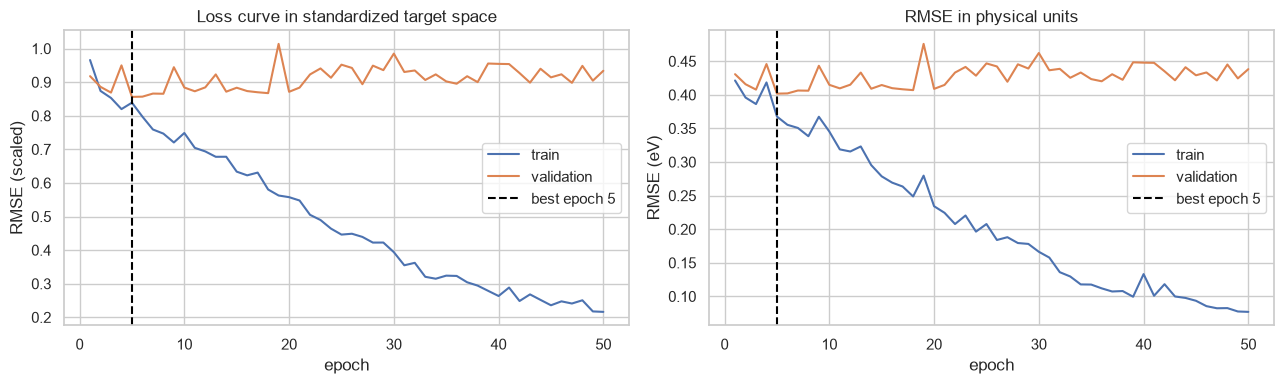

Final epochs:
 epoch  train_rmse_scaled  val_rmse_scaled  train_rmse_eV  val_rmse_eV
    43            0.26812          0.89858        0.09982      0.42169
    44            0.25179          0.93993        0.09767      0.44110
    45            0.23574          0.91432        0.09344      0.42908
    46            0.24741          0.92335        0.08543      0.43331
    47            0.24097          0.89803        0.08228      0.42143
    48            0.25057          0.94851        0.08252      0.44512
    49            0.21743          0.90444        0.07749      0.42444
    50            0.21609          0.93384        0.07691      0.43824


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history["epoch"], history["train_rmse_scaled"], label="train")
axes[0].plot(history["epoch"], history["val_rmse_scaled"], label="validation")
axes[0].axvline(best_epoch, color="black", linestyle="--", label=f"best epoch {best_epoch}")
axes[0].set(title="Loss curve in standardized target space", xlabel="epoch", ylabel="RMSE (scaled)")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_rmse_eV"], label="train")
axes[1].plot(history["epoch"], history["val_rmse_eV"], label="validation")
axes[1].axvline(best_epoch, color="black", linestyle="--", label=f"best epoch {best_epoch}")
axes[1].set(title="RMSE in physical units", xlabel="epoch", ylabel="RMSE (eV)")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Final epochs:")
print(history.tail(8).round(5).to_string(index=False))

## 4. Attention-map interpretation

The first validation example is selected by position before inspection. The
attention map shows which input characters the first layer used when forming
each token representation. A bright cell means more attention weight.

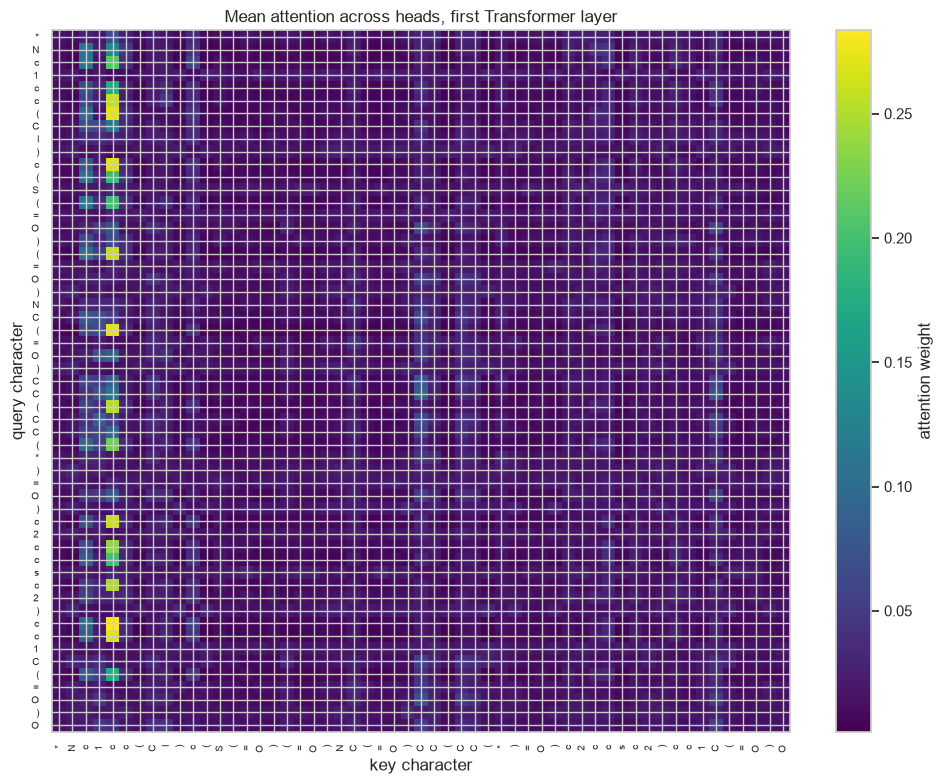

Validation example position: 0
PSMILES: *Nc1cc(Cl)c(S(=O)(=O)NC(=O)CC(CC(*)=O)c2ccsc2)cc1C(=O)O
true gap (eV): 8.9289
model prediction (eV): 8.31273365020752


In [12]:
transformer.eval()
ATTENTION_VALIDATION_POSITION = 0
example_tokens = torch.from_numpy(X_val[ATTENTION_VALIDATION_POSITION:ATTENTION_VALIDATION_POSITION + 1]).to(DEVICE)
with torch.no_grad():
    _, attention = transformer(example_tokens, return_attention=True)

attention = attention[0].detach().cpu().numpy()
mean_attention = attention.mean(axis=0)
valid_positions = int((X_val[ATTENTION_VALIDATION_POSITION] != PAD_IDX).sum())
chars_for_example = [inv_vocab.get(int(idx), UNK_TOKEN) for idx in X_val[ATTENTION_VALIDATION_POSITION, :valid_positions]]

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(mean_attention[:valid_positions, :valid_positions], cmap="viridis", aspect="auto")
ax.set_xticks(range(valid_positions))
ax.set_xticklabels(chars_for_example, rotation=90, fontsize=7)
ax.set_yticks(range(valid_positions))
ax.set_yticklabels(chars_for_example, fontsize=7)
ax.set(title="Mean attention across heads, first Transformer layer", xlabel="key character", ylabel="query character")
fig.colorbar(image, ax=ax, label="attention weight")
plt.tight_layout()
plt.show()

print("Validation example position:", ATTENTION_VALIDATION_POSITION)
print("PSMILES:", df.loc[val_idx[ATTENTION_VALIDATION_POSITION], "psmiles"])
print("true gap (eV):", float(df.loc[val_idx[ATTENTION_VALIDATION_POSITION], TARGET]))
with torch.no_grad():
    pred = inverse_target(predict_scaled(transformer, make_loader(X_val[ATTENTION_VALIDATION_POSITION:ATTENTION_VALIDATION_POSITION + 1], y_val[ATTENTION_VALIDATION_POSITION:ATTENTION_VALIDATION_POSITION + 1], batch_size=1, shuffle=False)))[0]
print("model prediction (eV):", float(pred))

## 5. Learned sequence embeddings and PCA

PCA is fitted on training embeddings only. The plot is a diagnostic, not proof
that the embedding coordinates have direct chemical meaning.

embedding shape: (555, 64)
PCA explained variance ratio: [0.907  0.0206]
cumulative explained variance: [0.907  0.9276]


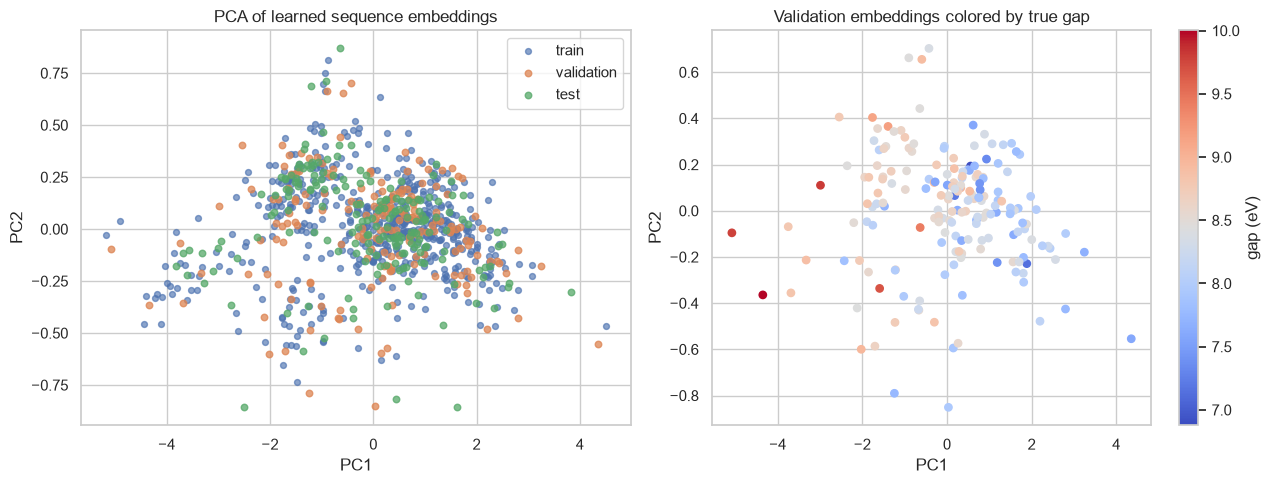

In [13]:
@torch.no_grad()
def extract_embeddings(model, tokens: np.ndarray, batch_size: int = 128) -> np.ndarray:
    model.eval()
    chunks = []
    for start in range(0, len(tokens), batch_size):
        batch = torch.from_numpy(tokens[start:start + batch_size].astype(np.int64)).to(DEVICE)
        chunks.append(model.encode(batch).detach().cpu().numpy())
    return np.concatenate(chunks)

Z_train = extract_embeddings(transformer, X_train)
Z_val = extract_embeddings(transformer, X_val)
Z_test = extract_embeddings(transformer, X_test)

embedding_pca = PCA(n_components=2, random_state=GLOBAL_SEED).fit(Z_train)
P_train = embedding_pca.transform(Z_train)
P_val = embedding_pca.transform(Z_val)
P_test = embedding_pca.transform(Z_test)

print("embedding shape:", Z_train.shape)
print("PCA explained variance ratio:", embedding_pca.explained_variance_ratio_.round(4))
print("cumulative explained variance:", embedding_pca.explained_variance_ratio_.cumsum().round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(P_train[:, 0], P_train[:, 1], s=18, alpha=0.65, label="train")
axes[0].scatter(P_val[:, 0], P_val[:, 1], s=22, alpha=0.75, label="validation")
axes[0].scatter(P_test[:, 0], P_test[:, 1], s=22, alpha=0.75, label="test")
axes[0].set(title="PCA of learned sequence embeddings", xlabel="PC1", ylabel="PC2")
axes[0].legend()

scatter = axes[1].scatter(P_val[:, 0], P_val[:, 1], c=y_val_raw, s=28, cmap="coolwarm")
axes[1].set(title="Validation embeddings colored by true gap", xlabel="PC1", ylabel="PC2")
fig.colorbar(scatter, ax=axes[1], label="gap (eV)")
plt.tight_layout()
plt.show()

## 6. Final test evaluation and baseline comparison

The final predictions are produced once, after the checkpoint is locked. The
strongest earlier baseline in Section 3 was a `StandardScaler + LinearRegression`
model using the ten honest numeric calculated properties. It is refit here on
the same row split so the comparison is visible in the notebook.

Transformer metrics (eV):
                R2     MAE     MSE    RMSE
train       0.3862  0.2841  0.1352  0.3677
validation  0.2800  0.3010  0.1614  0.4018
test        0.2508  0.2972  0.2038  0.4515

Final comparison:
                                                       test R2  test MAE  test MSE  test RMSE
Tiny Transformer (PSMILES)                              0.2508    0.2972    0.2038     0.4515
Linear baseline, same 555-row train budget              0.2334    0.3050    0.2086     0.4567
Section 3-style linear baseline, 740-row train budget   0.2494    0.3011    0.2042     0.4519


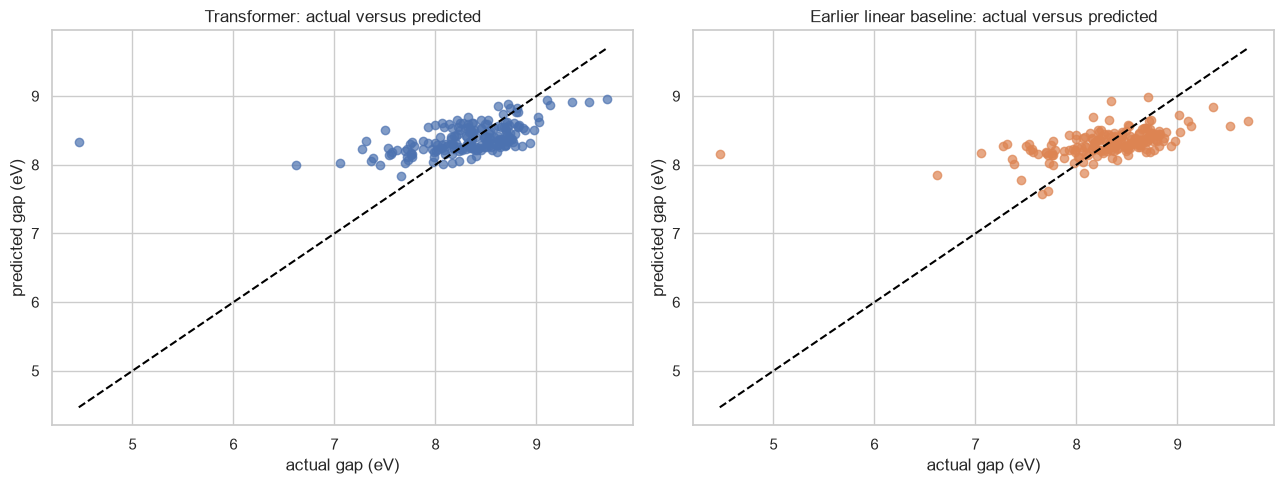

In [14]:
train_pred = inverse_target(predict_scaled(transformer, train_eval_loader))
val_pred = inverse_target(predict_scaled(transformer, val_loader))
test_pred = inverse_target(predict_scaled(transformer, test_loader))

transformer_metrics = pd.DataFrame({
    "train": regression_metrics(y_train_raw, train_pred),
    "validation": regression_metrics(y_val_raw, val_pred),
    "test": regression_metrics(y_test_raw, test_pred),
}).T
print("Transformer metrics (eV):")
print(transformer_metrics.round(4).to_string())

honest_features = [
    "Energy_Hatree",
    "es",
    "Isotropic_Polarizability_au",
    "Inner_energy_correction_Hatree",
    "Thermal_correction_to_Enthalpy_Hatree",
    "Thermal_correction_to_Gibbs_Free_Energy_Hatree",
    "Entropy_Hatree",
    "Dipole_Debye",
    "Gibbs_Free_Energy_Hatree",
    "Enthalpy_Hatree",
]

def fit_linear_baseline(feature_frame, train_rows, test_rows):
    model = LinearRegression()
    scaler = StandardScaler()
    x_train = scaler.fit_transform(feature_frame.iloc[train_rows])
    x_test = scaler.transform(feature_frame.iloc[test_rows])
    model.fit(x_train, df.iloc[train_rows][TARGET])
    prediction = model.predict(x_test)
    return regression_metrics(df.iloc[test_rows][TARGET], prediction), prediction

feature_frame = df[honest_features].astype(float)
section3_baseline_metrics, section3_baseline_pred = fit_linear_baseline(feature_frame, train_val_idx, test_idx)
same_budget_metrics, _ = fit_linear_baseline(feature_frame, train_idx, test_idx)

comparison = pd.DataFrame({
    "test R2": {
        "Tiny Transformer (PSMILES)": transformer_metrics.loc["test", "R2"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["R2"],
        "Section 3-style linear baseline, 740-row train budget": section3_baseline_metrics["R2"],
    },
    "test MAE": {
        "Tiny Transformer (PSMILES)": transformer_metrics.loc["test", "MAE"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["MAE"],
        "Section 3-style linear baseline, 740-row train budget": section3_baseline_metrics["MAE"],
    },
    "test MSE": {
        "Tiny Transformer (PSMILES)": transformer_metrics.loc["test", "MSE"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["MSE"],
        "Section 3-style linear baseline, 740-row train budget": section3_baseline_metrics["MSE"],
    },
    "test RMSE": {
        "Tiny Transformer (PSMILES)": transformer_metrics.loc["test", "RMSE"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["RMSE"],
        "Section 3-style linear baseline, 740-row train budget": section3_baseline_metrics["RMSE"],
    },
})
print("\nFinal comparison:")
print(comparison.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test_raw, test_pred, alpha=0.7)
axes[0].plot([y_test_raw.min(), y_test_raw.max()], [y_test_raw.min(), y_test_raw.max()], color="black", linestyle="--")
axes[0].set(title="Transformer: actual versus predicted", xlabel="actual gap (eV)", ylabel="predicted gap (eV)")

axes[1].scatter(y_test_raw, section3_baseline_pred, alpha=0.7, color="#dd8452")
axes[1].plot([y_test_raw.min(), y_test_raw.max()], [y_test_raw.min(), y_test_raw.max()], color="black", linestyle="--")
axes[1].set(title="Earlier linear baseline: actual versus predicted", xlabel="actual gap (eV)", ylabel="predicted gap (eV)")
plt.tight_layout()
plt.show()

## 7. Critical answers

**1. What did the token and data audit show?**

The valid dataset contains 926 rows after removing 74 rows with
`Energy_Hatree == 0`. PSMILES strings are short, with a training 99th
percentile length of about 83 characters; this made character-level
tokenization practical. The target has a narrow central range around 8.3 eV
and a few lower outliers near 4.47 eV. Sequence length alone has weak
correlation with the target, while several calculated numeric properties have
much stronger correlations. The model is therefore learning from structure
text, not from those numeric calculated properties.

**2. Does the attention implementation satisfy the expected contract?**

Yes. The manual implementation returns output with the same shape as `v` and
weights with shape `(batch, heads, query tokens, key tokens)`. Padded key
positions are masked. The numerical check against PyTorch's fused reference
has a very small maximum absolute difference, so the implementation agrees
with the library function on the tested tensors.

**3. What does the attention map show, and what does it not show?**

The map shows where the first layer assigned attention weight for one fixed
validation PSMILES. Bright cells are strong attention connections. This is
useful evidence that the attention mechanism is not uniform, but it does not
prove a chemically causal explanation. Attention weights are model-dependent
and can change with seed, layer, and training. The map is best interpreted as
an internal diagnostic rather than a scientific discovery.

**4. How does the Transformer compare with the earlier baseline?**

The comparison table reports the Transformer, the same linear model trained on
the smaller 555-row Transformer budget, and the Section 3-style linear baseline
trained on 740 rows. This separates two differences: architecture and available
training rows. If the linear baseline has higher R2 or lower RMSE, the result
does not mean Transformers are useless; it means a character-level model with
few hundred training examples has limited advantage over a strong
calculation-to-calculation baseline. The sequence model's scientific promise
would be evaluated with more data and a split that tests new chemical families.

**5. What are the limitations?**

The split is random over calculated records, not over polymer families. The
target and features come from the same source, so the results do not establish
performance on genuinely new chemistry. The model is intentionally small, uses
character tokenization rather than chemistry-aware tokenization, and has only
555 training rows. The test score is a one-time estimate on 186 rows and should
not be generalized beyond this benchmark.

## 8. Critical AI review

**Suggestion accepted.** The review suggested adding an explicit check that the
manual attention implementation agrees with PyTorch's scaled dot-product
attention on masked inputs. I accepted it and included both shape checks and a
numerical comparison. This turns the attention code from a visual claim into a
testable implementation contract.

**Suggestion changed or rejected.** A tempting suggestion was to tune the
Transformer for 300 epochs and choose the best test score. I rejected that
because it would violate the homework's test-set discipline. The notebook uses
validation RMSE for checkpoint selection and reports the test result once. This
keeps the evaluation honest even if the final score is lower.